# Clase 11 — Policy gradient y actor-crítico: reforzar lo que salió bien

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Williams (1992, REINFORCE), en Sutton & Barto, cap. 13 (13.1–13.5: gradiente de política, REINFORCE, línea de base y actor-crítico), en Schulman et al. (2017, PPO) y en Stanford CS234 (Brunskill), clases 5 y 6, y CS224R, clases 3 a 5.

**La pregunta de hoy:** si en vez de aprender cuánto vale cada casilla aprendieras directamente qué tan seguido ir para cada lado, ¿cómo sabrías para dónde mover esas probabilidades?

En las clases 5 y 6 el agente aprendía **valores** ($V$, $Q$) y de ahí sacaba las flechas. Hoy aprende **las flechas mismas**, como probabilidades: una política estocástica $\pi(a \mid s)$ como la de la clase 2, pero con perillas que se pueden mover. Y la forma de moverlas se parece mucho a imitar (clase 10): hacer más probable lo que se hizo en las partidas que salieron bien. Vamos a ver:

1. **Preferencias y softmax**: cuatro números por casilla que se vuelven probabilidades.
2. **REINFORCE**: una actualización a mano, con números, y las flechas que se engrosan.
3. **REINFORCE como imitación ponderada**: clonar todo, clonar lo exitoso y pesar por el retorno.
4. **La línea de base**: cuánto tiembla el gradiente con y sin, y qué pasa con el aprendizaje.
5. **Actor-crítico**: un crítico que aprende $V$ con el $\delta$ de la clase 5 y un actor que aprende con él.
6. **PPO**: qué pasa con un paso grande sin recorte y con recorte.

Y un ejercicio: cambiar $\alpha$, la línea de base y el recorte.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda alrededor de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre, y fijamos una semilla. Las convenciones son las de las clases 3 a 6: **+1 al entrar a la salida**, la salida es absorbente y vale 0 (ahí ya no queda nada por cobrar), el primer paso no se descuenta y $\gamma = 0{,}99$. Las partidas **empiezan siempre en S** y duran como mucho 200 pasos, como en el juego: así cada curva mide lo que de verdad importa (salir desde S) y el aprendizaje entra en unos segundos.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)
GAMMA = 0.99
env = CaveEnv(max_steps=200)

La celda siguiente define las **herramientas** (softmax, jugar, REINFORCE, actor-crítico, la imitación ponderada, el paso de PPO y los dibujos). Está plegada: no hace falta leerla, solo ejecutarla.

Una aclaración importante: las funciones que **aprenden** solo juegan con `env.reset` y `env.step`, como un jugador en la cueva a oscuras. El mapa (`env.P`, `env.R`) lo usan solo `iteracion_de_valor` (la respuesta correcta $V^*$, como en la clase 4), `valor_de` (cuánto vale de verdad la política aprendida) y `gradiente_exacto` (para medir el ruido en la sección 4). Son nuestras reglas para medir; el agente nunca las ve.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import math, random
import matplotlib.patheffects as pe

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
COL_SIN, COL_CON, COL_AC, COL_GRIS = COLORES[1], COLORES[0], COLORES[2], "#777777"
DESP = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # (fila, columna) de ↑ → ↓ ←


# ---------- la respuesta correcta y el valor de una política (esto SÍ usa el mapa) ----------
def iteracion_de_valor(env, gamma, tol=1e-12):
    """Clase 4: V(s) <- max_a [R(s,a) + γ Σ P(s'|s,a) V(s')]."""
    V = np.zeros(env.nS)
    while True:
        V_nuevo = (env.R + gamma * env.P @ V).max(axis=1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            return V_nuevo
        V = V_nuevo


def softmax(theta):
    """π(a|s) = e^θ(s,a) / Σ_b e^θ(s,b), casilla por casilla (fila por fila)."""
    theta = np.asarray(theta, dtype=float)
    z = np.exp(theta - theta.max(axis=-1, keepdims=True))
    return z / z.sum(axis=-1, keepdims=True)


def valor_de(env, theta, gamma=0.99):
    """V^π con el mapa (clases 3 y 4): V = (I − γ P^π)^(-1) R^π. Sin tope de pasos."""
    pi = softmax(theta)
    Ppi = np.einsum("sa,sat->st", pi, env.P); Rpi = (pi * env.R).sum(axis=1)
    return np.linalg.solve(np.eye(env.nS) - gamma * Ppi, Rpi)


def gradiente_exacto(env, theta, gamma=0.99):
    """Hacia dónde apunta, en promedio, el gradiente que estima REINFORCE desde S (calculado con el mapa):
    Σ_s visitas(s) Σ_a π(a|s) [Q^π(s,a) − V^π(s)] (1[a] − π(·|s))."""
    pi = softmax(theta)
    Ppi = np.einsum("sa,sat->st", pi, env.P); Rpi = (pi * env.R).sum(axis=1)
    V = np.linalg.solve(np.eye(env.nS) - gamma * Ppi, Rpi)
    Q = env.R + gamma * env.P @ V
    Pq = Ppi.copy(); Pq[env.goal] = 0
    mu = np.zeros(env.nS); mu[env.start] = 1
    visitas = np.linalg.solve(np.eye(env.nS) - Pq.T, mu); visitas[env.goal] = 0
    return visitas[:, None] * pi * (Q - V[:, None]), V


def pasos_de(v, gamma=0.99):
    """Si el único premio es el +1 al entrar, V = γ^(n−1): un camino de n pasos."""
    return 1 + np.log(v) / np.log(gamma)


# ---------- jugar: lo único que tiene el agente ----------
def elegir(fila, rng):
    """Sortea una acción con probabilidades softmax(fila)."""
    m = max(fila); e = [math.exp(x - m) for x in fila]
    u = rng.random() * sum(e); a, acum = 0, e[0]
    while u > acum and a < 3:
        a += 1; acum += e[a]
    return a


def jugar(env, theta, rng):
    """Una partida desde S (como mucho env.max_steps pasos). Devuelve la lista de experiencias (s, a, r, s')."""
    th = theta.tolist() if isinstance(theta, np.ndarray) else theta
    s = env.reset(); partida = []
    while True:
        a = elegir(th[s], rng)
        s2, r, fin, info = env.step(a)
        partida.append((s, a, r, s2))
        s = s2
        if fin:
            return partida


def salio(partida, env):
    return partida[-1][3] == env.goal


def camino_de(partida):
    return [partida[0][0]] + [x[3] for x in partida]


def retornos(partida, gamma=0.99):
    """G_t de cada paso, de atrás para adelante: G_t = r_t + γ G_{t+1}."""
    G, out = 0.0, []
    for s, a, r, s2 in reversed(partida):
        G = r + gamma * G
        out.append(G)
    return out[::-1]


def gradiente_partida(theta, partida, base=None, gamma=0.99):
    """Lo que una partida le pide a θ: Σ_t (G_t − b(s_t)) (1[a_t] − π(·|s_t)). base=None: sin línea de base."""
    pi = softmax(theta); g = np.zeros_like(pi)
    S = np.array([x[0] for x in partida]); A = np.array([x[1] for x in partida])
    peso = np.array(retornos(partida, gamma)) - (0.0 if base is None else np.asarray(base)[S])
    empuje = -pi[S]; empuje[np.arange(len(S)), A] += 1          # ∇ log π(a|s) = 1[a] − π(·|s), un renglón por paso
    np.add.at(g, S, peso[:, None] * empuje)
    return g


# ---------- aprender ----------
def reinforce(env, alfa, n_partidas, semilla, lote=10, linea_base=False, alfa_v=0.1, gamma=0.99, fotos=()):
    """REINFORCE: juega un lote de partidas con la política actual, suma lo que pide cada una y mueve θ:
        θ <- θ + α · promedio del lote de Σ_t (G_t − b(s_t)) (1[a_t] − π(·|s_t))
    linea_base=True: b(s) = retorno promedio desde s (se actualiza con b(s) += α_v (G − b(s)) después de cada lote).
    Devuelve θ, b, V^π(S) después de cada lote (con el mapa, para medir), pasos y salida de cada partida, y fotos de θ."""
    rng = random.Random(semilla)
    theta = np.zeros((env.nS, env.nA)); b = np.zeros(env.nS)
    VS, pasos, exito, snap = [], [], [], {0: theta.copy()} if 0 in fotos else {}
    for k in range(n_partidas // lote):
        partidas = [jugar(env, theta, rng) for _ in range(lote)]
        g = sum(gradiente_partida(theta, p, b if linea_base else None, gamma) for p in partidas) / lote
        theta = theta + alfa * g
        for p in partidas:
            pasos.append(len(p)); exito.append(salio(p, env))
            for (s, a, r, s2), G in zip(p, retornos(p, gamma)):
                b[s] += alfa_v * (G - b[s])
        VS.append(valor_de(env, theta, gamma)[env.start])
        if (k + 1) * lote in fotos:
            snap[(k + 1) * lote] = theta.copy()
    return {"theta": theta, "b": b, "VS": np.array(VS), "pasos": np.array(pasos), "exito": np.array(exito), "fotos": snap}


def actor_critico(env, alfa, alfa_v, n_partidas, semilla, gamma=0.99, cada=10):
    """Actor-crítico de un paso. Después de CADA paso (s, a, r, s'):
        δ = r + γ V(s') − V(s)        (el error de la clase 5; V(salida) = 0)
        crítico: V(s) += α_v δ        (TD(0), clase 5)
        actor:   θ(s,·) += α δ (1[a] − π(·|s))
    Devuelve θ, V del crítico, V^π(S) cada 'cada' partidas (con el mapa, para medir), pasos y salida de cada partida."""
    rng = random.Random(semilla)
    th = [[0.0] * env.nA for _ in range(env.nS)]; V = [0.0] * env.nS
    VS, pasos, exito = [], [], []
    for k in range(n_partidas):
        s = env.reset()
        while True:
            fila = th[s]; a = elegir(fila, rng)
            s2, r, fin, info = env.step(a)
            delta = r + (0.0 if s2 == env.goal else gamma * V[s2]) - V[s]
            V[s] += alfa_v * delta
            m = max(fila); e = [math.exp(x - m) for x in fila]; z = sum(e)
            for c in range(env.nA):
                fila[c] += alfa * delta * ((c == a) - e[c] / z)
            s = s2
            if fin:
                break
        pasos.append(env.t); exito.append(info["reached_goal"])
        if (k + 1) % cada == 0:
            VS.append(valor_de(env, np.array(th), gamma)[env.start])
    return {"theta": np.array(th), "V": np.array(V), "VS": np.array(VS), "pasos": np.array(pasos), "exito": np.array(exito)}


def imitar(env, partidas, peso, gamma=0.99):
    """Imitación por conteo (clase 10): π(a|s) = (peso de las veces que se hizo a en s) / (peso de las veces que se estuvo en s).
    peso="todas": cada paso pesa 1 (clonar todo); "exitosas": pesa 1 si la partida salió, 0 si no;
    "G": cada paso pesa su retorno G_t (lo que pide REINFORCE). Casillas sin datos: las 4 flechas iguales."""
    C = np.zeros((env.nS, env.nA))
    for p in partidas:
        S = [x[0] for x in p]; A = [x[1] for x in p]
        if peso == "todas":
            w = np.ones(len(p))
        elif peso == "exitosas":
            w = np.full(len(p), float(salio(p, env)))
        else:
            w = np.array(retornos(p, gamma))
        np.add.at(C, (S, A), w)
    n = C.sum(axis=1, keepdims=True)
    pi = np.where(n > 0, C / np.maximum(n, 1e-300), 0.25)
    return np.log(np.maximum(pi, 1e-12))                # θ = log π: softmax(θ) devuelve π


def ppo_actualizar(theta_vieja, base, lote, lr, pasadas, eps=None, gamma=0.99):
    """Una actualización 'grande': muchas pasadas de gradiente sobre el MISMO lote, con la ventaja A = G_t − b(s_t).
    Cada pasada sube Σ razón·A, con razón = π_nueva(a|s) / π_vieja(a|s).
    eps=None: sin recorte. Con eps: una muestra deja de empujar cuando su razón salió de [1 − ε, 1 + ε]
    hacia el lado que le conviene (es lo que hace el mínimo con la razón recortada de PPO).
    Devuelve θ nueva y la razón final de cada muestra."""
    S, A, ADV = [], [], []
    for p in lote:
        for (s, a, r, s2), G in zip(p, retornos(p, gamma)):
            S.append(s); A.append(a); ADV.append(G - base[s])
    S, A, ADV = np.array(S), np.array(A), np.array(ADV)
    pi_vieja = softmax(theta_vieja)[S, A]
    theta = theta_vieja.copy(); n = len(S)
    for _ in range(pasadas):
        pi = softmax(theta); razon = pi[S, A] / pi_vieja
        activa = np.ones(n, bool) if eps is None else ~(((ADV > 0) & (razon > 1 + eps)) | ((ADV < 0) & (razon < 1 - eps)))
        w = np.where(activa, razon * ADV, 0.0) / len(lote)
        empuje = -pi[S]; empuje[np.arange(n), A] += 1
        g = np.zeros_like(theta); np.add.at(g, S, w[:, None] * empuje)
        theta = theta + lr * g
    return theta, softmax(theta)[S, A] / pi_vieja


def primera_vez(VS, umbral, cada=10):
    """Partidas jugadas hasta que V^π(S) llegó al umbral por primera vez (None si nunca)."""
    i = np.flatnonzero(np.asarray(VS) >= umbral)
    return int((i[0] + 1) * cada) if i.size else None


# ---------- dibujos ----------
def plot_cave(env, values=None, path=None, ax=None, title=None, cmap="magma", clim=None, mark=None):
    """env.plot + escala de color elegible (calculada sin la salida) y círculos opcionales."""
    ax = env.plot(values=values, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[np.arange(env.nS) != env.goal]
            clim = (v.min(), v.max()) if v.max() - v.min() > 1e-12 else (v.max() - 1, v.max())
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        for m in np.atleast_1d(mark):
            r, c = env.free[int(m)]
            ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    return ax


def plot_flechas(env, theta, ax, values=None, title=None, clim=(0, 0.83), casillas=None, color="#00e5ff"):
    """Las flechas de la cueva como probabilidades: en cada casilla, cuatro flechas con grosor y largo según π(a|s)."""
    pi = softmax(theta)
    plot_cave(env, values=values, ax=ax, title=title, clim=clim if values is not None else None)
    ax.texts[-1].set_text("")                                  # sacamos la S para que se vean las flechas
    for s, (r, c) in enumerate(env.free):
        if s == env.goal or (casillas is not None and s not in casillas):
            continue
        for a, (dr, dc) in enumerate(DESP):
            p = pi[s, a]
            if p < 0.04:
                continue
            L = 0.14 + 0.34 * p
            ax.arrow(c, r, dc * L, dr * L, width=0.02 + 0.16 * p, head_width=0.08 + 0.26 * p, head_length=0.06 + 0.12 * p,
                     length_includes_head=True, color=color, alpha=0.95, lw=0)
    sr, sc = env.free[env.start]
    ax.plot(sc, sr, "s", mfc="none", mec="w", mew=1.5, ms=17)
    return ax


def banda(ax, x, y, color, label, ls="-"):
    """Promedio sobre semillas y banda de ± 1 desvío."""
    m, sd = y.mean(0), y.std(0)
    ax.plot(x, m, color=color, label=label, ls=ls)
    ax.fill_between(x, m - sd, m + sd, color=color, alpha=0.15, lw=0)

La respuesta correcta, como en la clase 4: $V^*$ por iteración de valor, con el mapa. Y, para tener una vara de abajo, cuánto vale tirar el dado (las cuatro flechas iguales).

In [4]:
V_estrella = iteracion_de_valor(env, GAMMA)
V_dado = valor_de(env, np.zeros((env.nS, env.nA)), GAMMA)
print(f"V*(S)            = {V_estrella[env.start]:.4f}   (un camino de {pasos_de(V_estrella[env.start]):.0f} pasos)")
print(f"V(S) con el dado = {V_dado[env.start]:.4f}")

V*(S)            = 0.8262   (un camino de 20 pasos)
V(S) con el dado = 0.0136


## 1. Preferencias y softmax

En la clase 2 la política era una tabla de probabilidades $\pi(a \mid s)$. Para poder **moverla** de a poco, no guardamos las probabilidades directamente: guardamos **cuatro preferencias** por casilla, $\theta(s, a)$, una por flecha, que pueden ser cualquier número. La función **softmax** las vuelve probabilidades:

$$\pi(a \mid s) = \frac{e^{\theta(s,a)}}{\sum_b e^{\theta(s,b)}}$$

Más preferencia, más probabilidad; todas positivas y suman 1. Con todas las preferencias iguales, las cuatro flechas valen 1/4: el dado.

### Paso 1 — Las probabilidades de una casilla, con $\theta$ dados

Tomamos la casilla S y le damos preferencias a mano: $\theta(S, \cdot) = (\uparrow -1,\ \rightarrow 1,\ \downarrow 0{,}5,\ \leftarrow -1)$. Hacemos la cuenta paso a paso.

In [5]:
theta_S = np.array([-1.0, 1.0, 0.5, -1.0])
e = np.exp(theta_S)
pi_S = e / e.sum()
print("θ(S, ·)      = " + "   ".join(f"{ACTION_NAMES[a]} {theta_S[a]:+.2f}" for a in range(4)))
print("e^θ          = " + "   ".join(f"{ACTION_NAMES[a]} {e[a]:.4f}" for a in range(4)) + f"     suma = {e.sum():.4f}")
print("π(·|S)       = " + "   ".join(f"{ACTION_NAMES[a]} {pi_S[a]:.4f}" for a in range(4)) + f"     suma = {pi_S.sum():.4f}")
print(f"\nla misma cuenta con la herramienta: {np.round(softmax(theta_S), 4)}")
print(f"si sumamos 5 a las cuatro preferencias, no cambia nada: {np.round(softmax(theta_S + 5), 4)}")

θ(S, ·)      = ↑ -1.00   → +1.00   ↓ +0.50   ← -1.00
e^θ          = ↑ 0.3679   → 2.7183   ↓ 1.6487   ← 0.3679     suma = 5.1028
π(·|S)       = ↑ 0.0721   → 0.5327   ↓ 0.3231   ← 0.0721     suma = 1.0000

la misma cuenta con la herramienta: [0.0721 0.5327 0.3231 0.0721]
si sumamos 5 a las cuatro preferencias, no cambia nada: [0.0721 0.5327 0.3231 0.0721]


La derecha, con la preferencia más alta, se lleva un poco más de la mitad; las dos paredes, con $-1$, se reparten menos del 10 %. Lo que importa son las **diferencias** entre preferencias, no su valor absoluto.

### Paso 2 — Por qué se puede optimizar directamente

Si multiplicamos las preferencias por un número cada vez más grande, la política pasa suavemente del dado a casi siempre lo mismo. Ninguna probabilidad salta: cada pequeño cambio en $\theta$ da un pequeño cambio en $\pi$. Eso es lo que permite **subir la cuesta** con gradientes, como al entrenar una red: no hace falta pasar por $Q$ ni por un máximo que salta de una flecha a otra (*policy-based*, basado en la política).

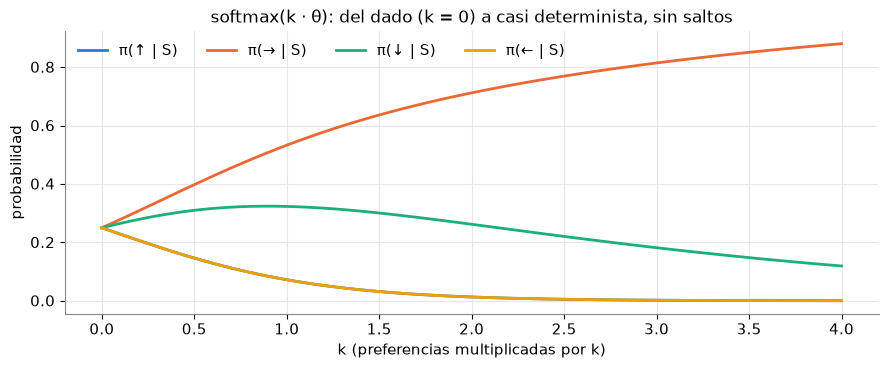

k = 0:  ↑ 0.250   → 0.250   ↓ 0.250   ← 0.250
k = 1:  ↑ 0.072   → 0.533   ↓ 0.323   ← 0.072
k = 2:  ↑ 0.013   → 0.712   ↓ 0.262   ← 0.013
k = 4:  ↑ 0.000   → 0.880   ↓ 0.119   ← 0.000


In [6]:
escalas = np.linspace(0, 4, 81)
P_esc = np.array([softmax(k * theta_S) for k in escalas])
fig, ax = plt.subplots(figsize=(9, 3.8))
for a in range(4):
    ax.plot(escalas, P_esc[:, a], color=COLORES[a], label=f"π({ACTION_NAMES[a]} | S)")
ax.set_xlabel("k (preferencias multiplicadas por k)"); ax.set_ylabel("probabilidad")
ax.set_title("softmax(k · θ): del dado (k = 0) a casi determinista, sin saltos"); ax.legend(frameon=False, ncol=4)
plt.tight_layout(); plt.show()
for k in [0, 1, 2, 4]:
    print(f"k = {k}:  " + "   ".join(f"{ACTION_NAMES[a]} {softmax(k * theta_S)[a]:.3f}" for a in range(4)))

### Paso 3 — La cueva entera con flechas que son probabilidades

Este va a ser el dibujo de toda la clase: en cada casilla, cuatro flechas, **más gruesas y más largas cuanto más probables**. A la izquierda, $\theta = 0$ en todas las casillas (el dado: cuatro flechas iguales en todas partes, incluso contra las paredes). A la derecha, la política con las preferencias de recién en S y $\theta = 0$ en el resto.

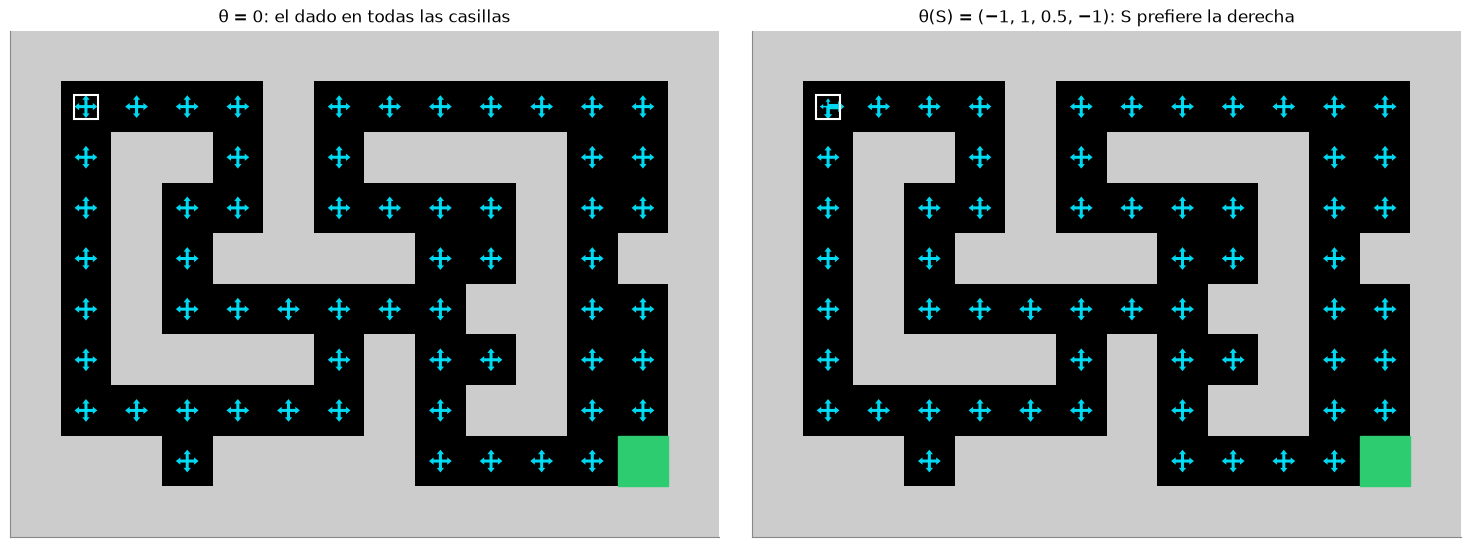

V(S) de la izquierda = 0.0136   V(S) de la derecha = 0.0150


In [7]:
theta_0 = np.zeros((env.nS, env.nA))
theta_1 = theta_0.copy(); theta_1[env.start] = theta_S
fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
plot_flechas(env, theta_0, axs[0], title="θ = 0: el dado en todas las casillas")
plot_flechas(env, theta_1, axs[1], title="θ(S) = (−1, 1, 0.5, −1): S prefiere la derecha")
plt.tight_layout(); plt.show()
print(f"V(S) de la izquierda = {valor_de(env, theta_0)[env.start]:.4f}   V(S) de la derecha = {valor_de(env, theta_1)[env.start]:.4f}")

Cambiar una sola casilla ya mueve un poco el valor de S, pero muy poco: el dado sigue mandando en las otras 58. Aprender es encontrar las 60 × 4 = 240 preferencias que hacen que las flechas gruesas lleven a la salida. La pregunta es **para dónde mover cada una**.

## 2. REINFORCE: subir la probabilidad de lo que salió bien

La idea de REINFORCE (Williams, 1992) entra en una línea: después de una partida, **empujar $\theta$ para que las acciones que se tomaron sean más probables, en proporción al retorno $G$** que vino después. Para cada paso $(s_t, a_t)$ de la partida:

$$\theta(s_t, \cdot) \leftarrow \theta(s_t, \cdot) + \alpha\, G_t\, \nabla \log \pi(a_t \mid s_t)$$

Con softmax, la dirección de empuje es muy simple: $\nabla \log \pi(a \mid s) = \mathbf{1}[a] - \pi(\cdot \mid s)$. Sube la preferencia de la acción tomada (en $1 - \pi(a \mid s)$) y baja la de las otras (en su propia probabilidad). Si la partida no llegó a la salida, $G = 0$ y no se mueve nada.

### Paso 1 — Una partida que salió

Jugamos con el dado desde S hasta encontrar una partida que llegue a la salida en menos de 200 pasos.

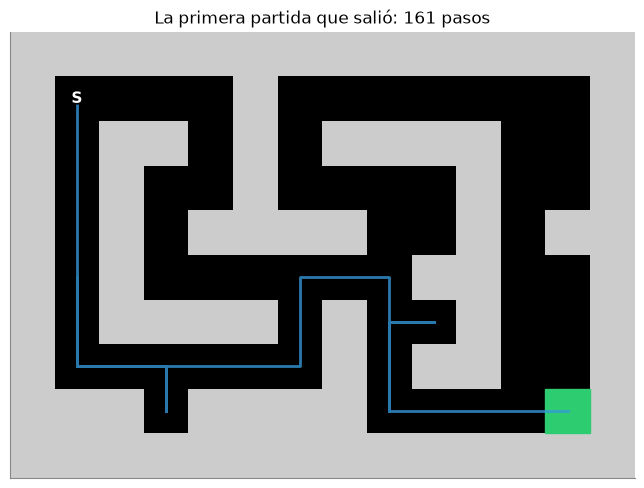

intentos hasta la primera que salió: 13   pasos: 161   G desde S = 0.99^160 = 0.2003
veces que pasó por S en esta partida: 1


In [8]:
rng = random.Random(4)
intentos = 0
while True:
    intentos += 1
    partida = jugar(env, theta_0, rng)
    if salio(partida, env):
        break
Gs = retornos(partida)
fig, ax = plt.subplots(figsize=(7.5, 5))
plot_cave(env, path=camino_de(partida), ax=ax, title=f"La primera partida que salió: {len(partida)} pasos")
plt.tight_layout(); plt.show()
print(f"intentos hasta la primera que salió: {intentos}   pasos: {len(partida)}   G desde S = 0.99^{len(partida) - 1} = {Gs[0]:.4f}")
print(f"veces que pasó por S en esta partida: {sum(1 for x in partida if x[0] == env.start)}")

### Paso 2 — Una actualización a mano

Tomamos solo el **primer paso** de esa partida: en S, con $\theta(S, \cdot) = 0$ (el dado), el agente eligió una acción $a$, y lo que cobró desde ahí hasta el final fue $G_0$. Con $\alpha = 1$:

1. $\pi(\cdot \mid S)$ con $\theta = 0$.
2. La dirección de empuje: $\mathbf{1}[a] - \pi(\cdot \mid S)$.
3. El paso: $\alpha\, G_0\, (\mathbf{1}[a] - \pi)$.
4. Las preferencias nuevas y sus probabilidades.

In [9]:
ALFA_MANO = 1.0
s0, a0, r0, s1 = partida[0]
th_viejo = theta_0[s0].copy()
pi_viejo = softmax(th_viejo)
empuje = -pi_viejo.copy(); empuje[a0] += 1
paso = ALFA_MANO * Gs[0] * empuje
th_nuevo = th_viejo + paso
pi_nuevo = softmax(th_nuevo)
fmt = lambda v, f="{:+.4f}": "   ".join(f"{ACTION_NAMES[a]} " + f.format(v[a]) for a in range(4))
print(f"casilla S = {env.free[s0]},  acción tomada a = {ACTION_NAMES[a0]},  G_0 = {Gs[0]:.4f},  α = {ALFA_MANO}")
print(f"   1. π(·|S) con θ = 0       : {fmt(pi_viejo, '{:.4f}')}")
print(f"   2. 1[a] − π               : {fmt(empuje)}")
print(f"   3. α · G · (1[a] − π)     : {fmt(paso)}")
print(f"   4. θ(S, ·) nuevo          : {fmt(th_nuevo)}")
print(f"      π(·|S) nuevo           : {fmt(pi_nuevo, '{:.4f}')}")
print(f"\nπ({ACTION_NAMES[a0]} | S): {pi_viejo[a0]:.4f} -> {pi_nuevo[a0]:.4f}")

casilla S = (1, 1),  acción tomada a = ↓,  G_0 = 0.2003,  α = 1.0
   1. π(·|S) con θ = 0       : ↑ 0.2500   → 0.2500   ↓ 0.2500   ← 0.2500
   2. 1[a] − π               : ↑ -0.2500   → -0.2500   ↓ +0.7500   ← -0.2500
   3. α · G · (1[a] − π)     : ↑ -0.0501   → -0.0501   ↓ +0.1502   ← -0.0501
   4. θ(S, ·) nuevo          : ↑ -0.0501   → -0.0501   ↓ +0.1502   ← -0.0501
      π(·|S) nuevo           : ↑ 0.2369   → 0.2369   ↓ 0.2894   ← 0.2369

π(↓ | S): 0.2500 -> 0.2894


La acción que se tomó pasó de 0,25 a un poco más; las otras tres bajaron lo mismo entre las tres. El empuje es chico porque $G_0$ es chico: la partida tardó mucho, y el $+1$ llegó muy descontado. Una partida más corta habría empujado más.

### Paso 3 — Toda la partida, y después muchas

REINFORCE hace esa misma cuenta en **cada paso** de la partida (todas las visitas a cada casilla) y suma. A la izquierda, las flechas antes; en el medio, después de esta única partida (con $\alpha = 1$): se engrosan a lo largo del camino que salió. A la derecha, después de 300 partidas de REINFORCE, en lotes de 10 partidas por actualización y $\alpha = 3$; el color es el valor verdadero de cada casilla con esa política.

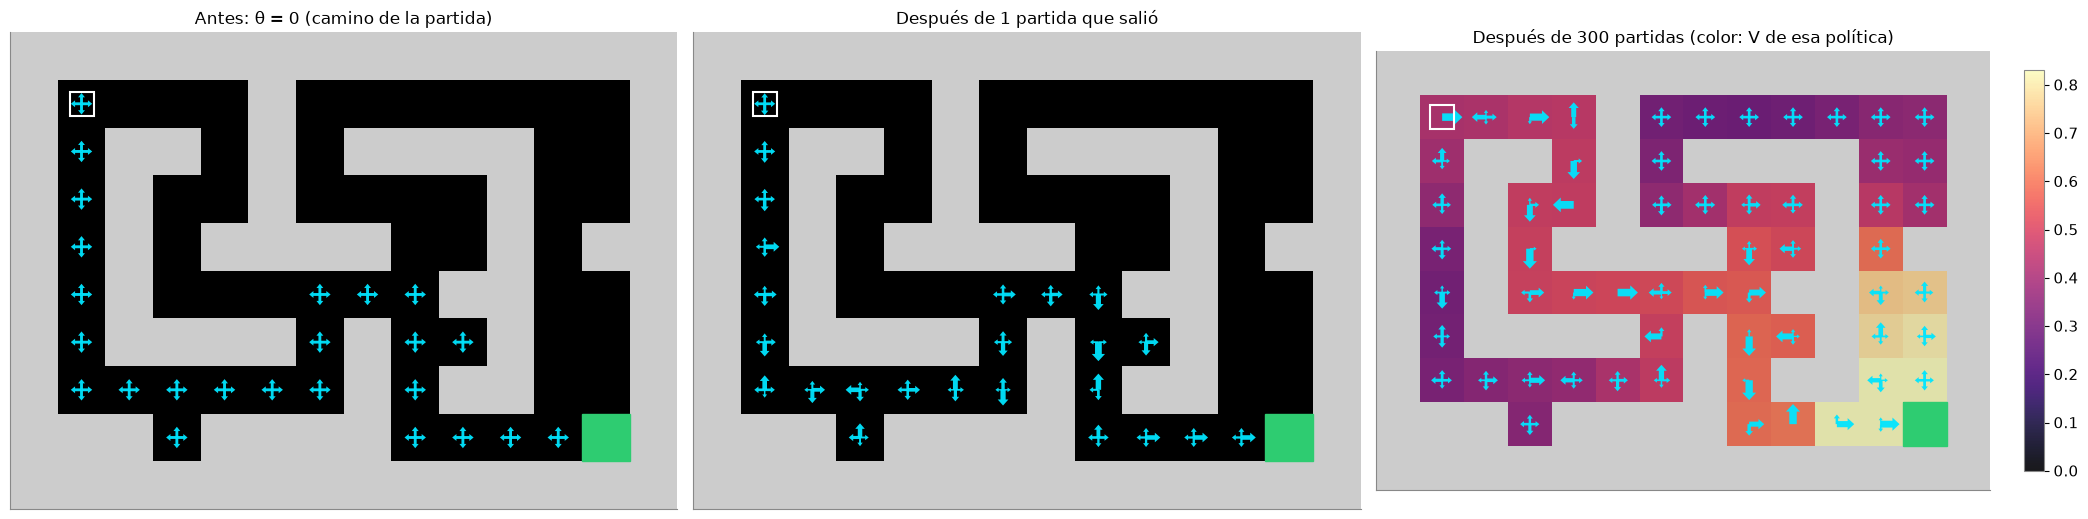

π(·|S) después de 1 partida: ↑ 0.2369   → 0.2369   ↓ 0.2894   ← 0.2369
mayor probabilidad en una casilla del camino después de 1 partida: 0.7612
V(S): dado = 0.0136   tras 1 partida = 0.0974   tras 300 partidas = 0.4276   V* = 0.8262
partidas que salieron: primeras 50 = 2%   últimas 50 = 100%


In [10]:
theta_una = theta_0 + ALFA_MANO * gradiente_partida(theta_0, partida)
rf_corto = reinforce(env, alfa=3.0, n_partidas=300, semilla=0, fotos=(300,))
casillas_camino = set(camino_de(partida))

fig, axs = plt.subplots(1, 3, figsize=(21, 5.4))
plot_flechas(env, theta_0, axs[0], casillas=casillas_camino, title="Antes: θ = 0 (camino de la partida)")
plot_flechas(env, theta_una, axs[1], casillas=casillas_camino, title="Después de 1 partida que salió")
plot_flechas(env, rf_corto["theta"], axs[2], values=valor_de(env, rf_corto["theta"]),
             title="Después de 300 partidas (color: V de esa política)")
plt.tight_layout(); plt.show()

pi_una = softmax(theta_una)
print(f"π(·|S) después de 1 partida: {fmt(pi_una[env.start], '{:.4f}')}")
print(f"mayor probabilidad en una casilla del camino después de 1 partida: {pi_una[list(casillas_camino)].max():.4f}")
print(f"V(S): dado = {V_dado[env.start]:.4f}   tras 1 partida = {valor_de(env, theta_una)[env.start]:.4f}   "
      f"tras 300 partidas = {rf_corto['VS'][-1]:.4f}   V* = {V_estrella[env.start]:.4f}")
print(f"partidas que salieron: primeras 50 = {rf_corto['exito'][:50].mean():.0%}   últimas 50 = {rf_corto['exito'][-50:].mean():.0%}")

Una sola partida mueve poco, pero en la dirección del camino que funcionó: las flechas del camino se engrosan y $V(S)$ pasa de 0,014 a casi 0,1. Con 300 partidas el agente ya sale en todas las partidas (al principio salía en el 2 %), pero todavía da rodeos: $V(S) \approx 0{,}43$ equivale a un camino de unos 85 pasos, contra los 20 del más corto. Afinar lleva más partidas (sección 4). Nadie le dijo al agente cuánto vale cada casilla: solo hizo más probable lo que venía antes de cobrar.

## 3. REINFORCE como imitación ponderada

En la clase 10 imitábamos: mirar qué hizo alguien en cada casilla y copiar esas frecuencias (clonar el comportamiento, *behavior cloning*). REINFORCE se parece mucho: también hace más probable lo que se hizo. La diferencia es **cuánto pesa cada paso**:

- Si $G$ fuera 1 siempre, REINFORCE sería clonar todo lo que se jugó.
- Con $G$ de verdad, una partida que no salió pesa 0, y una que salió rápido pesa más que una que salió tarde.

Para verlo sin esperar a que REINFORCE dé muchos pasitos, saltamos directo a adonde apuntan: jugamos 2000 partidas con el dado desde S y **contamos** qué hizo en cada casilla, con tres pesos distintos. (REINFORCE da pasitos hacia la tercera.)

1. **Clonar todas** las partidas: cada paso pesa 1.
2. **Clonar las exitosas**: pesa 1 si la partida salió, 0 si no.
3. **Pesar por $G$**: cada paso pesa su retorno $G_t$.

In [11]:
rng = random.Random(10)
partidas_dado = [jugar(env, theta_0, rng) for _ in range(2000)]
ok = np.array([salio(p, env) for p in partidas_dado])
largos_ok = np.array([len(p) for p in partidas_dado])[ok]
theta_im = {peso: imitar(env, partidas_dado, peso) for peso in ["todas", "exitosas", "G"]}
V_im = {peso: valor_de(env, th) for peso, th in theta_im.items()}
NOMBRE_IM = {"todas": "clonar todas", "exitosas": "clonar las exitosas", "G": "pesar por G"}

print(f"partidas del dado que salieron: {ok.sum()} de 2000 ({ok.mean():.1%});  pasos de las que salieron: "
      f"mediana {np.median(largos_ok):.0f}, mín. {largos_ok.min()}, máx. {largos_ok.max()}")
print(f"\n{'política':22s} {'V(S)':>8s} {'V medio (59 casillas)':>22s}")
ng = np.arange(env.nS) != env.goal
print(f"{'el dado (los datos)':22s} {V_dado[env.start]:>8.4f} {V_dado[ng].mean():>22.4f}")
for peso in theta_im:
    print(f"{NOMBRE_IM[peso]:22s} {V_im[peso][env.start]:>8.4f} {V_im[peso][ng].mean():>22.4f}")
print(f"{'V* (la mejor)':22s} {V_estrella[env.start]:>8.4f} {V_estrella[ng].mean():>22.4f}")

partidas del dado que salieron: 48 de 2000 (2.4%);  pasos de las que salieron: mediana 168, mín. 76, máx. 199

política                   V(S)  V medio (59 casillas)
el dado (los datos)      0.0136                 0.1936
clonar todas             0.0127                 0.1930
clonar las exitosas      0.2442                 0.5359
pesar por G              0.2923                 0.5791
V* (la mejor)            0.8262                 0.9122


Clonar todo devuelve el dado: copiamos a un jugador que tira el dado y sale un jugador que tira el dado. Quedarse solo con las exitosas ya mejora mucho, y pesar por $G$ mejora un poco más, porque dentro de las exitosas favorece lo que llevó a salir antes. Las dos últimas son mucho mejores que el jugador del que aprendieron: **imitar ponderando permite superar al que se imita**.

Veamos las flechas de las dos últimas, con el valor de cada casilla de fondo.

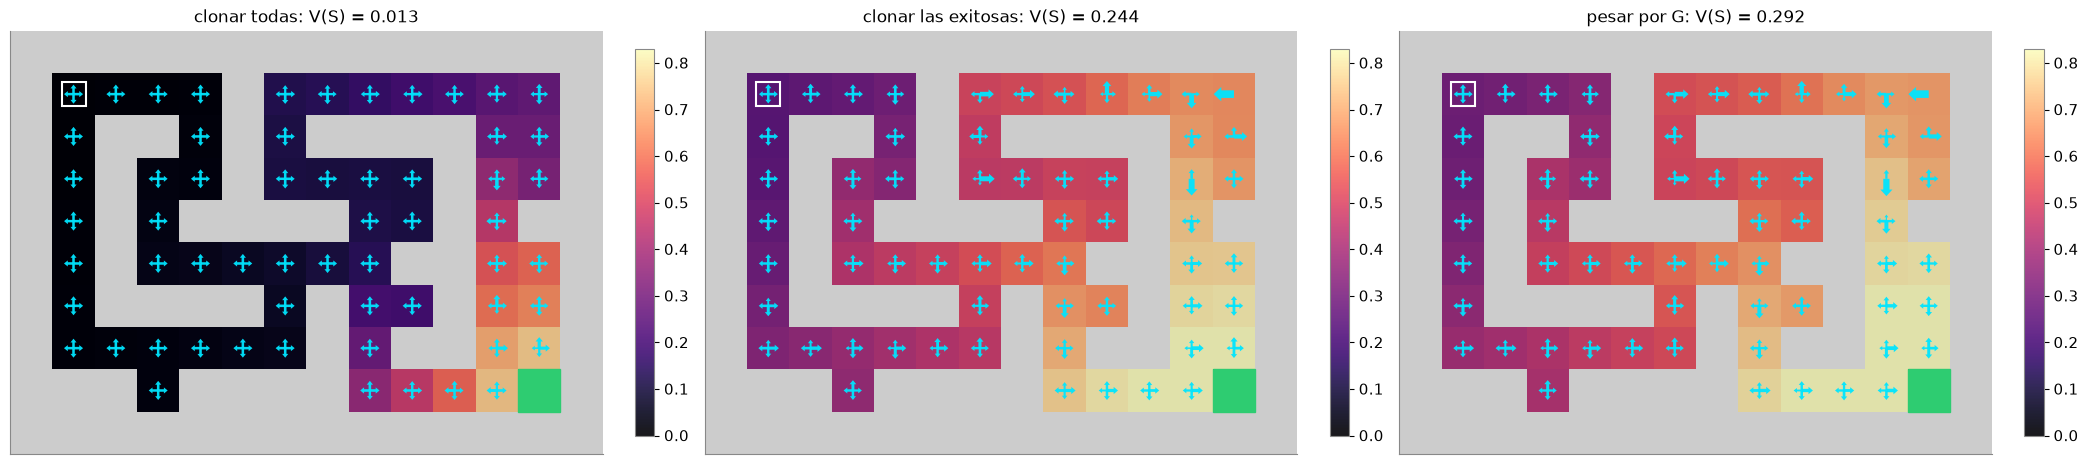

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(21, 5.4))
for ax, peso in zip(axs, ["todas", "exitosas", "G"]):
    plot_flechas(env, theta_im[peso], ax, values=V_im[peso], title=f"{NOMBRE_IM[peso]}: V(S) = {V_im[peso][env.start]:.3f}")
plt.tight_layout(); plt.show()

Con un solo lote de datos del dado no se llega lejos: en muchas casillas las flechas siguen casi parejas, porque las partidas exitosas del dado también daban vueltas por todos lados. Lo que hace REINFORCE es **repetir**: imita ponderado, juega con la política nueva (que sale más seguido y más rápido), vuelve a imitar ponderado. Lo probamos con tres rondas de 2000 partidas, pesando por $G$.

In [13]:
rng = random.Random(11)
theta_r = theta_0.copy()
print(f"ronda 0 (el dado): V(S) = {valor_de(env, theta_r)[env.start]:.4f}")
for ronda in range(1, 4):
    datos = [jugar(env, theta_r, rng) for _ in range(2000)]
    exito_r = np.mean([salio(p, env) for p in datos])
    theta_r = imitar(env, datos, "G")
    print(f"ronda {ronda}: con los datos de la ronda anterior (salieron {exito_r:.0%}) -> V(S) = {valor_de(env, theta_r)[env.start]:.4f}")
print(f"V*(S) = {V_estrella[env.start]:.4f}")

ronda 0 (el dado): V(S) = 0.0136


ronda 1: con los datos de la ronda anterior (salieron 3%) -> V(S) = 0.2910


ronda 2: con los datos de la ronda anterior (salieron 86%) -> V(S) = 0.3656


ronda 3: con los datos de la ronda anterior (salieron 98%) -> V(S) = 0.4137
V*(S) = 0.8262


Cada ronda imita a un jugador mejor que el de la ronda anterior, porque el jugador es él mismo, ya mejorado. Esa es la diferencia con la clase 10: allá los datos eran de otro y quedaban fijos; acá el agente **genera sus propios datos** y los pesa por cómo salieron.

## 4. La línea de base: mucho menos ruido

Cuando la política ya sale casi siempre, todas las partidas traen $G > 0$ y REINFORCE empuja **para arriba todo lo que hizo**, incluidos los rodeos. Lo que distingue una partida buena de una mala es solo cuánto más alto fue su $G$, y esa diferencia queda tapada por el empuje común. La solución es restar una **línea de base** (*baseline*) $b(s)$, el retorno que se espera desde esa casilla:

$$\theta(s_t, \cdot) \leftarrow \theta(s_t, \cdot) + \alpha\, \big(G_t - b(s_t)\big)\, \nabla \log \pi(a_t \mid s_t)$$

Ahora sube lo que salió **mejor que lo esperado** y baja lo que salió peor. En promedio no cambia hacia dónde apunta el gradiente, porque $\sum_a \pi(a \mid s)\, (\mathbf{1}[a] - \pi) = 0$: restar lo mismo a todas las acciones de una casilla no empuja hacia ninguna.

### Paso 1 — Cuánto tiembla el gradiente

Tomamos una política a medio aprender (REINFORCE sin línea de base, 100 partidas) y le pedimos su gradiente a 3000 partidas sueltas, sin aprender: cada partida da un gradiente distinto. Lo calculamos **sin** línea de base y **con** $b(s) = V^\pi(s)$, el retorno promedio verdadero desde cada casilla (lo calculamos con el mapa, solo para medir bien). Y comparamos con el gradiente verdadero (también con el mapa).

In [14]:
theta_medio = reinforce(env, alfa=3.0, n_partidas=100, semilla=0)["theta"]
g_true, V_medio = gradiente_exacto(env, theta_medio)
rng = random.Random(20)
N_GRAD = 3000
g_sin, g_con = [], []
for _ in range(N_GRAD):
    p = jugar(env, theta_medio, rng)
    g_sin.append(gradiente_partida(theta_medio, p)); g_con.append(gradiente_partida(theta_medio, p, base=V_medio))
g_sin, g_con = np.array(g_sin), np.array(g_con)

def varianza(gs):
    return float(((gs - gs.mean(0)) ** 2).sum(axis=(1, 2)).mean())

def coseno(x, y):
    return float((x * y).sum() / (np.linalg.norm(x) * np.linalg.norm(y) + 1e-300))

var_sin, var_con = varianza(g_sin), varianza(g_con)
print(f"política a medio aprender: V(S) = {V_medio[env.start]:.4f}")
print(f"varianza del gradiente de UNA partida:  sin línea de base = {var_sin:.3f}   con = {var_con:.3f}   "
      f"({var_sin / var_con:.0f} veces menos)")
for nombre, gs in [("sin", g_sin), ("con", g_con)]:
    lotes10 = np.mean([coseno(gs[i:i + 10].mean(0), g_true) for i in range(0, N_GRAD, 10)])
    print(f"   {nombre}: coseno con el gradiente verdadero  promedio de {N_GRAD} = {coseno(gs.mean(0), g_true):.3f}   "
          f"un lote de 10 (promedio) = {lotes10:.3f}")

política a medio aprender: V(S) = 0.3403
varianza del gradiente de UNA partida:  sin línea de base = 23.058   con = 4.204   (5 veces menos)
   sin: coseno con el gradiente verdadero  promedio de 3000 = 0.943   un lote de 10 (promedio) = 0.184
   con: coseno con el gradiente verdadero  promedio de 3000 = 0.989   un lote de 10 (promedio) = 0.487


El coseno mide si dos flechas en el espacio de las 240 preferencias apuntan para el mismo lado (1 = igual, 0 = perpendiculares). Veámoslo a medida que se juntan partidas: el coseno entre el promedio de las primeras $n$ partidas y el gradiente verdadero.

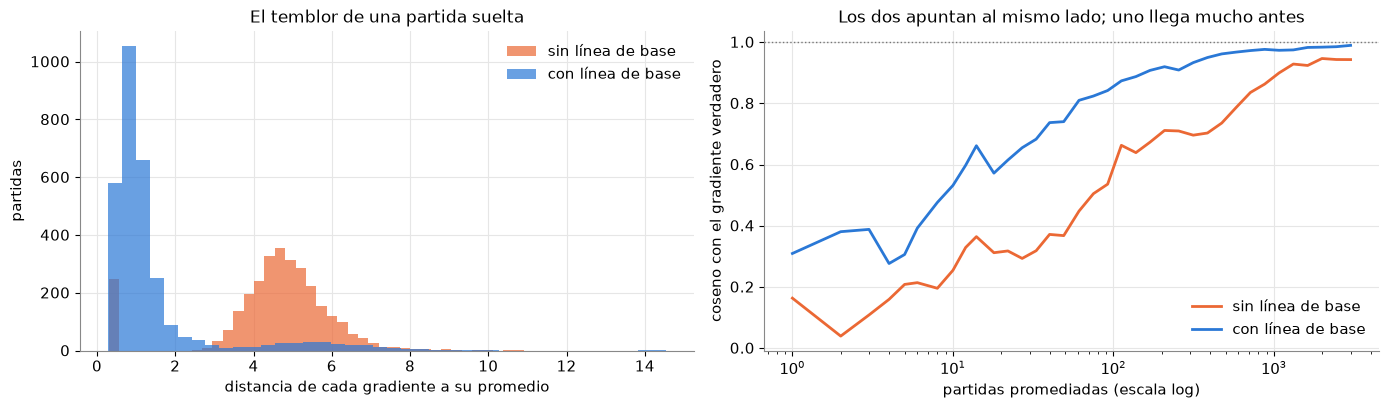

promediando    10 partidas:  coseno sin = 0.254   con = 0.532
promediando    92 partidas:  coseno sin = 0.536   con = 0.842
promediando  1075 partidas:  coseno sin = 0.899   con = 0.973
promediando  3000 partidas:  coseno sin = 0.943   con = 0.989


In [15]:
ns = np.unique(np.round(np.logspace(0, np.log10(N_GRAD), 40)).astype(int))
cs_sin = [coseno(g_sin[:n].mean(0), g_true) for n in ns]
cs_con = [coseno(g_con[:n].mean(0), g_true) for n in ns]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
norm_sin = np.sqrt(((g_sin - g_sin.mean(0)) ** 2).sum(axis=(1, 2)))
norm_con = np.sqrt(((g_con - g_con.mean(0)) ** 2).sum(axis=(1, 2)))
axs[0].hist(norm_sin, bins=40, color=COL_SIN, alpha=0.7, label="sin línea de base")
axs[0].hist(norm_con, bins=40, color=COL_CON, alpha=0.7, label="con línea de base")
axs[0].set_xlabel("distancia de cada gradiente a su promedio"); axs[0].set_ylabel("partidas")
axs[0].set_title("El temblor de una partida suelta"); axs[0].legend(frameon=False)
axs[1].plot(ns, cs_sin, color=COL_SIN, label="sin línea de base"); axs[1].plot(ns, cs_con, color=COL_CON, label="con línea de base")
axs[1].axhline(1, color=COL_GRIS, ls=":", lw=1); axs[1].set_xscale("log")
axs[1].set_xlabel("partidas promediadas (escala log)"); axs[1].set_ylabel("coseno con el gradiente verdadero")
axs[1].set_title("Los dos apuntan al mismo lado; uno llega mucho antes"); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()
for n in [10, 100, 1000, N_GRAD]:
    i = int(np.argmin(np.abs(ns - n)))
    print(f"promediando {ns[i]:5d} partidas:  coseno sin = {cs_sin[i]:.3f}   con = {cs_con[i]:.3f}")

Las dos versiones apuntan, en promedio, al mismo lado: las dos curvas suben hacia 1. Pero con línea de base el temblor de cada partida es varias veces más chico, y con unas 100 partidas apunta tan bien como sin línea de base con unas 1000.

### Paso 2 — ¿Y el aprendizaje?

Ahora aprendemos de verdad, con la línea de base que puede tener el agente: el **retorno promedio desde cada casilla**, aprendido con lo que juega ($b(s) \mathrel{+}= 0{,}1\,(G - b(s))$, como el Monte Carlo con $\alpha$ fijo de la clase 5). REINFORCE en lotes de 10 partidas, 1000 partidas, 8 semillas, con $\alpha = 3$ y con $\alpha = 10$. Decimos que **aprendió** cuando el valor verdadero de su política en S llega a 0,75 (más del 90 % de $V^*$).

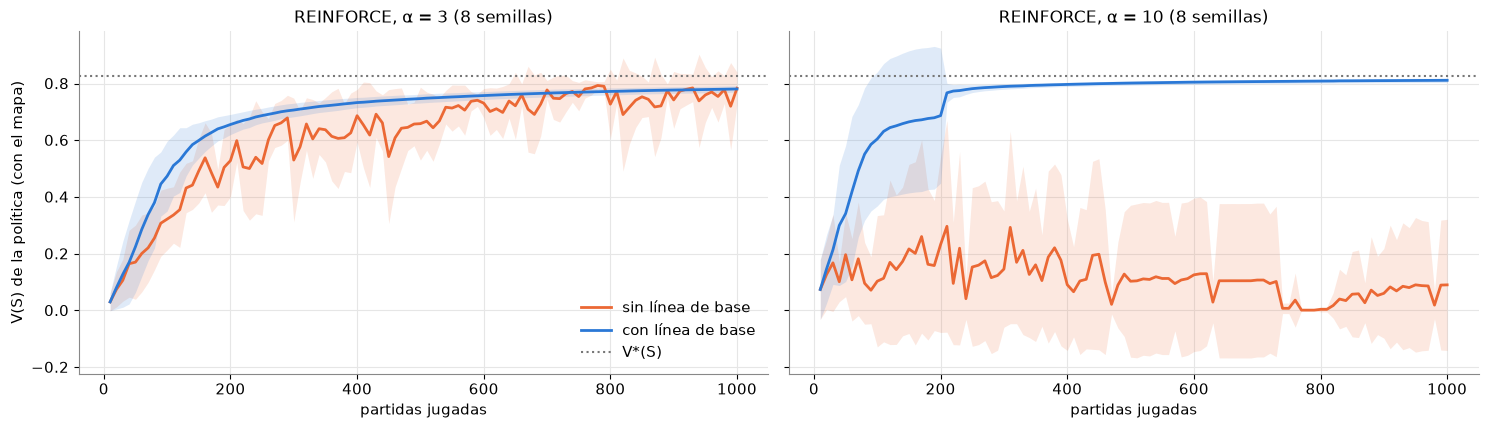

                               aprendió (V(S) ≥ 0,75) en  V(S) a las 200         V(S) final
α = 3    sin línea de base            mediana 430 partidas    0.528 ± 0.128     0.7834 ± 0.0565
α = 3    con línea de base            mediana 485 partidas    0.656 ± 0.036     0.7808 ± 0.0114
α = 10   sin línea de base     mediana 185 partidas, 4 nunca    0.232 ± 0.310     0.0902 ± 0.2310
α = 10   con línea de base            mediana 150 partidas    0.687 ± 0.238     0.8113 ± 0.0074
α = 10 sin línea de base, V(S) final de cada semilla: [0.001, 0.0, 0.0, 0.701, 0.0, 0.0, 0.0, 0.019]
V*(S) = 0.8262


In [16]:
SEMILLAS = range(8)
N_PART = 1000
UMBRAL = 0.75
curvas = {}
for alfa in [3.0, 10.0]:
    for lb in [False, True]:
        curvas[(alfa, lb)] = [reinforce(env, alfa, N_PART, sem, linea_base=lb) for sem in SEMILLAS]

x = np.arange(1, N_PART // 10 + 1) * 10
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
for ax, alfa in zip(axs, [3.0, 10.0]):
    for lb, col, nom in [(False, COL_SIN, "sin línea de base"), (True, COL_CON, "con línea de base")]:
        banda(ax, x, np.array([c["VS"] for c in curvas[(alfa, lb)]]), col, nom)
    ax.axhline(V_estrella[env.start], color=COL_GRIS, ls=":", lw=1.5, label="V*(S)")
    ax.set_title(f"REINFORCE, α = {alfa:g} (8 semillas)"); ax.set_xlabel("partidas jugadas")
axs[0].set_ylabel("V(S) de la política (con el mapa)"); axs[0].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print(f"{'':28s} {'aprendió (V(S) ≥ 0,75) en':>27s} {'V(S) a las 200':>15s} {'V(S) final':>18s}")
for (alfa, lb), cs in curvas.items():
    pv = [primera_vez(c["VS"], UMBRAL) for c in cs]
    nunca = sum(v is None for v in pv); pv_ok = [v for v in pv if v is not None]
    txt = (f"mediana {np.median(pv_ok):.0f} partidas" if pv_ok else "—") + (f", {nunca} nunca" if nunca else "")
    v200 = np.array([c["VS"][19] for c in cs]); vf = np.array([c["VS"][-1] for c in cs])
    print(f"α = {alfa:<4g} {'con' if lb else 'sin'} línea de base     {txt:>27s} {v200.mean():>8.3f} ± {v200.std():.3f} "
          f"{vf.mean():>10.4f} ± {vf.std():.4f}")
print("α = 10 sin línea de base, V(S) final de cada semilla:", [round(float(c["VS"][-1]), 3) for c in curvas[(10.0, False)]])
print(f"V*(S) = {V_estrella[env.start]:.4f}")

Con $\alpha = 3$ las dos versiones terminan cerca y llegan a 0,75 en una cantidad de partidas parecida, pero la de línea de base sube más parejo: a las 200 partidas va más arriba y las semillas se parecen mucho más entre sí (la banda es más angosta), mientras que la otra tiembla de lote a lote. Con $\alpha = 10$ la diferencia es de otro orden: sin línea de base, el empuje de todas las partidas es tan grande que la política se vuelve casi determinista antes de tiempo, y casi todas las semillas terminan trabadas lejos de la salida (algunas llegaron a 0,75 y después se derrumbaron); con línea de base, el mismo $\alpha$ aprende rápido y bien en las 8. Menos temblor significa que se puede **dar pasos más grandes** sin romper nada.

> Ojo con una sutileza de esta cueva: como el único premio es el $+1$ de la salida, una partida que no sale da $G = 0$ y sin línea de base no empuja nada. Eso hace que REINFORCE sin línea de base, partida por partida y con $\alpha$ bien elegido, aprenda sorprendentemente bien acá. La ventaja de la línea de base se ve cuando se promedian lotes, se buscan pasos grandes o el premio no es solo «llegar o no llegar».

## 5. Actor-crítico: un mapa de $V$ que juzga

REINFORCE tiene que esperar al final de la partida para saber $G$. En la clase 5 vimos cómo no esperar: TD(0) corrige $V$ en cada paso con el error

$$\delta = r + \gamma V(s') - V(s)$$

El **actor-crítico** usa dos tablas. El **crítico** aprende $V$ con TD(0), exactamente como en la clase 5. El **actor** son las preferencias $\theta$, y en vez de $G - b(s)$ usa $\delta$ como **ventaja** (*advantage*): «este paso salió mejor (o peor) de lo que el crítico esperaba».

$$\text{crítico: } V(s) \mathrel{+}= \alpha_V\, \delta \qquad\quad \text{actor: } \theta(s, \cdot) \mathrel{+}= \alpha\, \delta\, \big(\mathbf{1}[a] - \pi(\cdot \mid s)\big)$$

### Paso 1 — Actor-crítico contra REINFORCE

Las mismas 8 semillas y 1000 partidas desde S. Actor-crítico con $\alpha = 10$ y $\alpha_V = 0{,}5$, actualizando en cada paso; REINFORCE en lotes de 10 partidas con $\alpha = 10$ y línea de base, y sin línea de base con $\alpha = 3$ (el mejor de los dos que probamos para él).

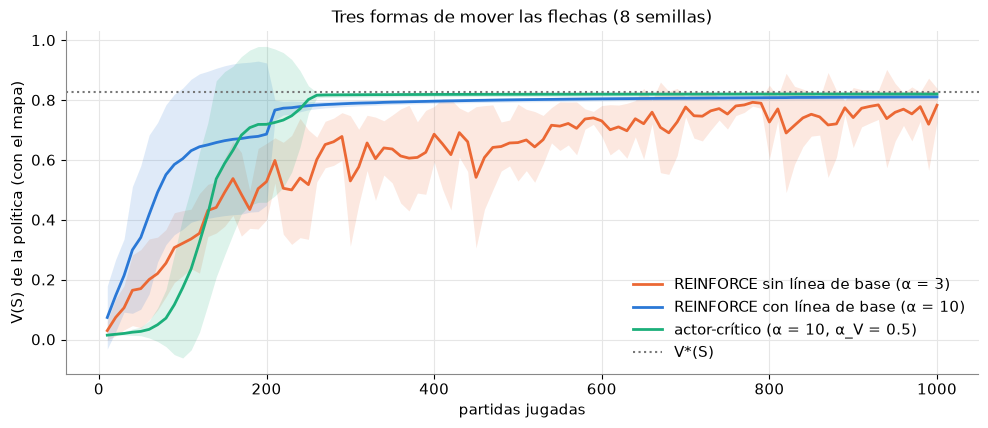

método                                       aprendió en (mediana, mín–máx)         V(S) final  pasos (últimas 100)
REINFORCE sin línea de base (α = 3)                           430 (300–600)     0.7834 ± 0.0565                 29.7
REINFORCE con línea de base (α = 10)                          150 (100–250)     0.8113 ± 0.0074                 21.8
actor-crítico (α = 10, α_V = 0.5)                             145 (100–260)     0.8210 ± 0.0072                 20.6
V*(S)                                                                           0.8262  (camino más corto: 20 pasos)


In [17]:
ALFA_AC, ALFA_V = 10.0, 0.5
corr_ac = [actor_critico(env, ALFA_AC, ALFA_V, N_PART, sem) for sem in SEMILLAS]
metodos = [("REINFORCE sin línea de base (α = 3)", curvas[(3.0, False)], COL_SIN),
           ("REINFORCE con línea de base (α = 10)", curvas[(10.0, True)], COL_CON),
           (f"actor-crítico (α = {ALFA_AC:g}, α_V = {ALFA_V})", corr_ac, COL_AC)]

fig, ax = plt.subplots(figsize=(10, 4.4))
for nom, cs, col in metodos:
    banda(ax, x, np.array([c["VS"] for c in cs]), col, nom)
ax.axhline(V_estrella[env.start], color=COL_GRIS, ls=":", lw=1.5, label="V*(S)")
ax.set_xlabel("partidas jugadas"); ax.set_ylabel("V(S) de la política (con el mapa)")
ax.set_title("Tres formas de mover las flechas (8 semillas)"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print(f"{'método':42s} {'aprendió en (mediana, mín–máx)':>32s} {'V(S) final':>18s} {'pasos (últimas 100)':>20s}")
for nom, cs, col in metodos:
    pv = [primera_vez(c["VS"], UMBRAL) for c in cs]; pv_ok = [v for v in pv if v is not None]
    nunca = sum(v is None for v in pv)
    txt = f"{np.median(pv_ok):.0f} ({min(pv_ok)}–{max(pv_ok)})" + (f", {nunca} nunca" if nunca else "")
    vf = np.array([c["VS"][-1] for c in cs]); pas = np.mean([c["pasos"][-100:].mean() for c in cs])
    print(f"{nom:42s} {txt:>32s} {vf.mean():>10.4f} ± {vf.std():.4f} {pas:>20.1f}")
print(f"{'V*(S)':42s} {'':>32s} {V_estrella[env.start]:>10.4f}  (camino más corto: {pasos_de(V_estrella[env.start]):.0f} pasos)")

El actor-crítico empieza más lento: al principio el crítico no sabe nada ($V = 0$ en todas partes), así que $\delta$ es 0 salvo en el último paso antes de la salida, y el valor tiene que viajar hacia atrás de a una casilla, como en TD de la clase 5. Cuando el crítico ya sabe algo, el actor aprende en cada paso y termina con la política más cerca de $V^*$ de las tres.

### Paso 2 — El crítico y el actor al final

A la izquierda, el mapa de $V$ que aprendió el crítico (semilla 0); en el medio, el valor verdadero de la política del actor, con sus flechas; a la derecha, $V^*$.

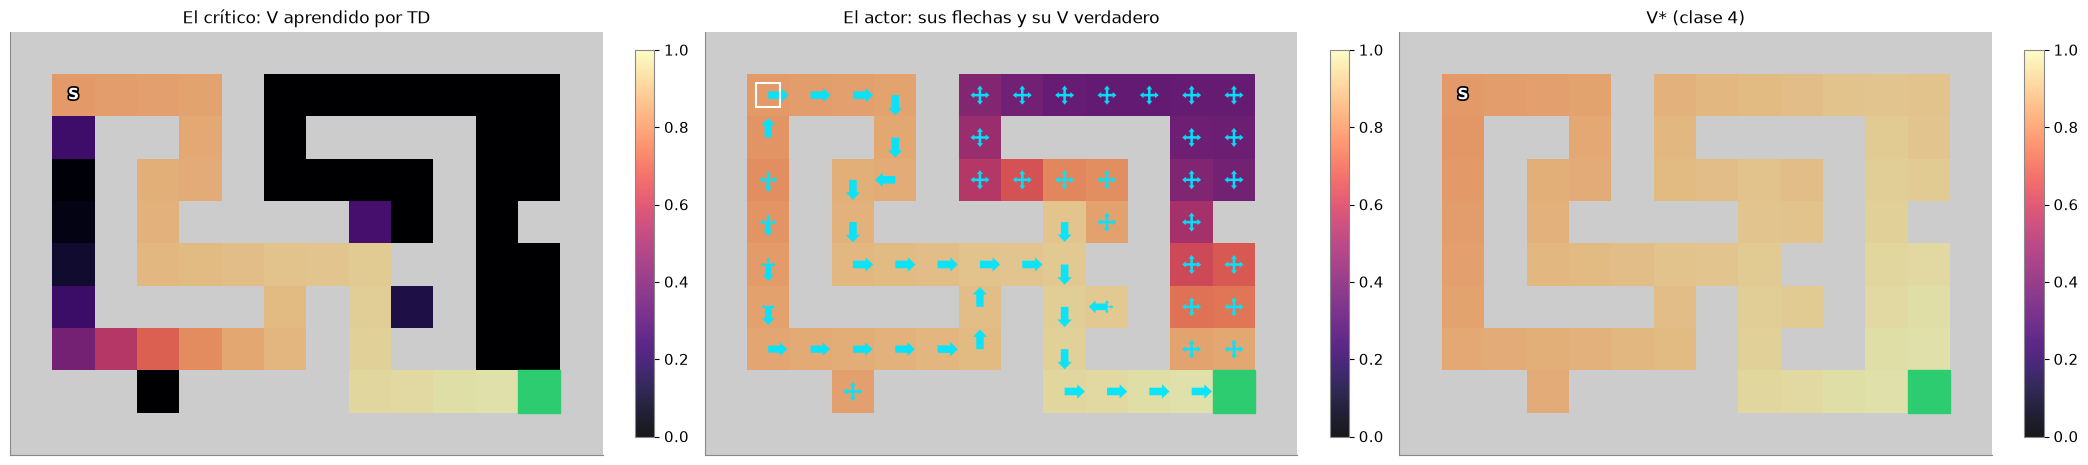

V(S): crítico = 0.8259   verdadero del actor = 0.8250   V* = 0.8262
π(·|S) del actor: ↑ 0.000   → 1.000   ↓ 0.000   ← 0.000
casillas donde el crítico está a menos de 0,05 del valor verdadero del actor: 39%


In [18]:
ac0 = corr_ac[0]
V_actor = valor_de(env, ac0["theta"])
fig, axs = plt.subplots(1, 3, figsize=(21, 5.4))
plot_cave(env, values=ac0["V"], ax=axs[0], clim=(0, 1), title="El crítico: V aprendido por TD")
plot_flechas(env, ac0["theta"], axs[1], values=V_actor, clim=(0, 1), title="El actor: sus flechas y su V verdadero")
plot_cave(env, values=V_estrella, ax=axs[2], clim=(0, 1), title="V* (clase 4)")
plt.tight_layout(); plt.show()

ng = np.arange(env.nS) != env.goal
pi_ac = softmax(ac0["theta"])
print(f"V(S): crítico = {ac0['V'][env.start]:.4f}   verdadero del actor = {V_actor[env.start]:.4f}   V* = {V_estrella[env.start]:.4f}")
print(f"π(·|S) del actor: {fmt(pi_ac[env.start], '{:.3f}')}")
print(f"casillas donde el crítico está a menos de 0,05 del valor verdadero del actor: "
      f"{np.mean(np.abs(ac0['V'] - V_actor)[ng] < 0.05):.0%}")

El crítico acierta sobre el camino que usa el actor y se equivoca lejos de él, como el mapa de visitas de la clase 6: solo sabe de donde pasa. Al actor no le importa, porque por esas casillas casi no pasa.

## 6. PPO: no alejarse demasiado de la política anterior

Jugar partidas cuesta. Sería tentador jugar un lote y **reutilizarlo muchas veces**: dar muchas pasadas de gradiente sobre las mismas partidas, en vez de un pasito. El problema es que, después de unas pasadas, la política ya no es la que jugó esas partidas, y seguir empujando con esos datos puede llevarla muy lejos, adonde nadie miró.

PPO (*Proximal Policy Optimization*, Schulman et al., 2017) mira, para cada paso del lote, la **razón** entre la probabilidad nueva y la vieja de la acción que se tomó:

$$\text{razón} = \frac{\pi_{\text{nueva}}(a \mid s)}{\pi_{\text{vieja}}(a \mid s)}$$

y la **recorta** en $[1 - \varepsilon,\ 1 + \varepsilon]$ (con $\varepsilon = 0{,}2$ es entre 0,8 y 1,2): cuando una acción buena ya se volvió 20 % más probable que antes, ese paso deja de empujar; lo mismo cuando una acción mala ya bajó 20 %. No vamos a derivarlo, solo a verlo funcionar.

### Paso 1 — La figura del recorte

Lo que PPO sube para un paso del lote es $\min(\text{razón} \cdot A,\ \text{recorte}(\text{razón}) \cdot A)$, con $A$ la ventaja. Para una acción con ventaja positiva, subir la razón paga hasta $1 + \varepsilon$ y después ya no paga más; con ventaja negativa, bajarla paga hasta $1 - \varepsilon$.

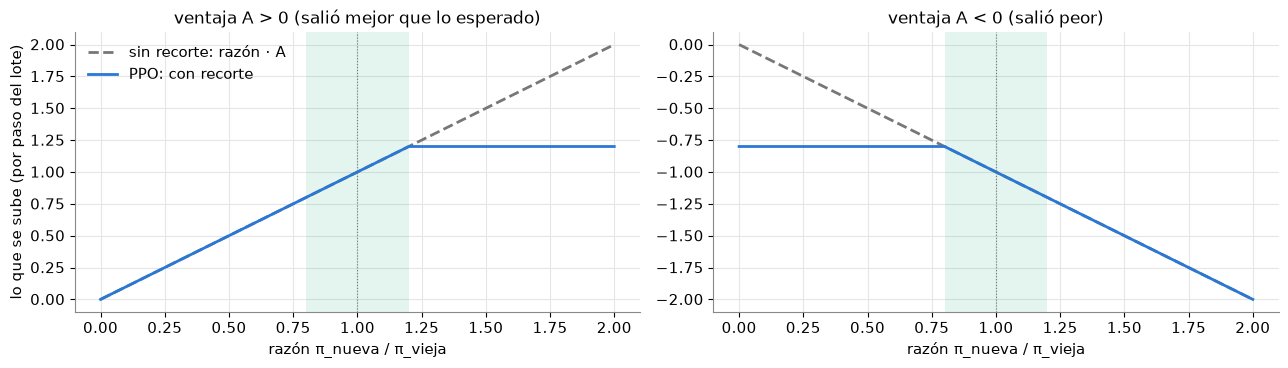

ε = 0.2: la banda verde es la razón entre 0.8 y 1.2


In [19]:
EPS = 0.2
r_ = np.linspace(0, 2, 401)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for ax, A, tit in [(axs[0], 1.0, "ventaja A > 0 (salió mejor que lo esperado)"), (axs[1], -1.0, "ventaja A < 0 (salió peor)")]:
    ax.axvspan(1 - EPS, 1 + EPS, color=COL_AC, alpha=0.12, lw=0)
    ax.plot(r_, r_ * A, color=COL_GRIS, ls="--", label="sin recorte: razón · A")
    ax.plot(r_, np.minimum(r_ * A, np.clip(r_, 1 - EPS, 1 + EPS) * A), color=COL_CON, label="PPO: con recorte")
    ax.axvline(1, color=COL_GRIS, lw=0.8, ls=":")
    ax.set_xlabel("razón π_nueva / π_vieja"); ax.set_title(tit)
axs[0].set_ylabel("lo que se sube (por paso del lote)"); axs[0].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
print(f"ε = {EPS}: la banda verde es la razón entre {1 - EPS:.1f} y {1 + EPS:.1f}")

### Paso 2 — Un paso grande, sin recorte y con recorte

Tomamos una política a medio aprender (REINFORCE con línea de base, 100 partidas) con su línea de base $b(s)$. Jugamos **un lote de 10 partidas** y le damos **50 pasadas** de gradiente con un paso de 1, con la ventaja $A = G_t - b(s_t)$. Una vez sin recorte y una vez con $\varepsilon = 0{,}2$. Repetimos con 20 lotes distintos y medimos el valor verdadero de S antes y después. Como control, también damos **una sola pasada** con un paso de 10.

In [20]:
base_ppo = reinforce(env, alfa=3.0, n_partidas=100, semilla=0, linea_base=True)
theta_v, b_v = base_ppo["theta"], base_ppo["b"]
V_antes = valor_de(env, theta_v)[env.start]
res_ppo = {}
for nombre, lr, pasadas, eps in [("sin recorte, 50 pasadas", 1.0, 50, None), ("con recorte, 50 pasadas", 1.0, 50, EPS),
                                 ("una pasada, paso 10 (sin recorte)", 10.0, 1, None), ("una pasada, paso 10 (con recorte)", 10.0, 1, EPS)]:
    fila = []
    for k in range(20):
        rng = random.Random(100 + k)
        lote = [jugar(env, theta_v, rng) for _ in range(10)]
        th_n, razon = ppo_actualizar(theta_v, b_v, lote, lr, pasadas, eps)
        fila.append((valor_de(env, th_n)[env.start], np.mean((razon >= 1 - EPS - 1e-9) & (razon <= 1 + EPS + 1e-9)), razon))
    res_ppo[nombre] = fila

print(f"política de partida: V(S) = {V_antes:.4f}")
print(f"{'actualización':36s} {'V(S) después: media [mín, máx]':>32s} {'mejoró':>8s} {'razones en [0,8; 1,2]':>22s}")
for nombre, fila in res_ppo.items():
    v = np.array([f[0] for f in fila]); banda_ = np.mean([f[1] for f in fila])
    print(f"{nombre:36s} {v.mean():>12.4f} [{v.min():.4f}, {v.max():.4f}] {np.sum(v > V_antes):>5d}/20 {banda_:>21.0%}")

política de partida: V(S) = 0.2178
actualización                          V(S) después: media [mín, máx]   mejoró  razones en [0,8; 1,2]
sin recorte, 50 pasadas                    0.0047 [0.0000, 0.0472]     0/20                    2%
con recorte, 50 pasadas                    0.3263 [0.1569, 0.4175]    18/20                   50%
una pasada, paso 10 (sin recorte)          0.2628 [0.0895, 0.4961]    12/20                   22%
una pasada, paso 10 (con recorte)          0.2628 [0.0895, 0.4961]    12/20                   22%


Sin recorte, 50 pasadas sobre el mismo lote **arruinan** la política: con 10 partidas de datos, el gradiente se cree demasiado lo que vio, empuja algunas acciones hasta probabilidad casi 1 y otras casi 0, y el valor de S se desploma. Con recorte, las mismas 50 pasadas mejoran la política casi siempre: cada paso del lote deja de empujar cuando su acción ya cambió lo suficiente. Con una sola pasada, el recorte no hace nada (en la primera pasada la razón es exactamente 1): **el recorte importa cuando se reutiliza un lote**, que es justamente lo que PPO quiere poder hacer.

Para ver dónde quedaron las razones, el histograma de un lote (en escala log). El recorte no es un candado: algunas razones se salen igual de la banda, porque en esta cueva varios pasos comparten la misma casilla y lo que empuja uno mueve también a los otros. Pero la mitad queda dentro de la banda y la mediana, cerca de 1; sin recorte, casi ninguna.

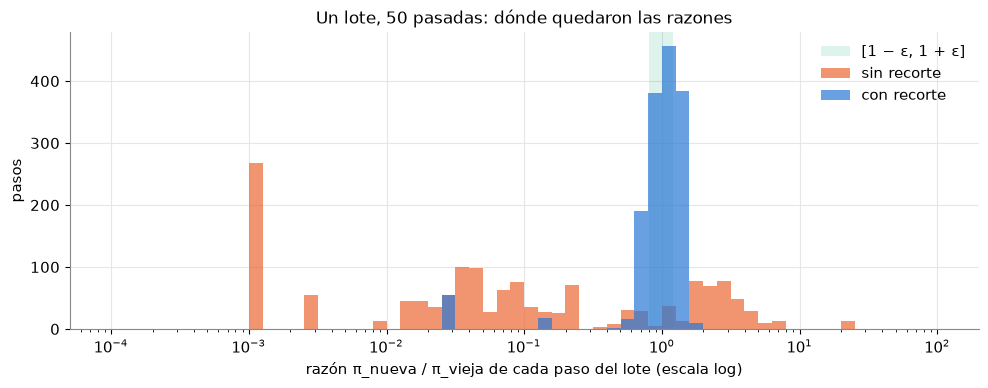

sin recorte, 50 pasadas: razón mediana = 0.070   mín. = 0.0011   máx. = 21.68   V(S) = 0.0001
con recorte, 50 pasadas: razón mediana = 1.043   mín. = 0.0291   máx. = 2.14   V(S) = 0.2417


In [21]:
bins = np.logspace(-4, 2, 61)
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(1 - EPS, 1 + EPS, color=COL_AC, alpha=0.15, lw=0, label="[1 − ε, 1 + ε]")
ax.hist(res_ppo["sin recorte, 50 pasadas"][0][2], bins=bins, color=COL_SIN, alpha=0.7, label="sin recorte")
ax.hist(res_ppo["con recorte, 50 pasadas"][0][2], bins=bins, color=COL_CON, alpha=0.7, label="con recorte")
ax.set_xscale("log"); ax.set_xlabel("razón π_nueva / π_vieja de cada paso del lote (escala log)"); ax.set_ylabel("pasos")
ax.set_title("Un lote, 50 pasadas: dónde quedaron las razones"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
for nombre in ["sin recorte, 50 pasadas", "con recorte, 50 pasadas"]:
    rz = res_ppo[nombre][0][2]
    print(f"{nombre}: razón mediana = {np.median(rz):.3f}   mín. = {rz.min():.4f}   máx. = {rz.max():.2f}   V(S) = {res_ppo[nombre][0][0]:.4f}")

Esta idea, no alejarse demasiado de la política que generó los datos, es la que se usa para ajustar modelos de lenguaje con RL: lo vamos a ver en las clases 12 y 13.

## ✍️ Ejercicio — Cambien $\alpha$, la línea de base y el recorte

La primera celda corre REINFORCE en lotes de 10 partidas con 4 semillas; la segunda da el paso grande de PPO sobre 20 lotes. Cambien los valores y ejecuten.

Antes de ejecutar, **predigan**: con $\alpha = 30$, ¿quién aguanta, con o sin línea de base? Si suben $\varepsilon$ a 1, ¿el paso grande se parece más al de con recorte o al de sin recorte? ¿Y con $\varepsilon = 0{,}05$?

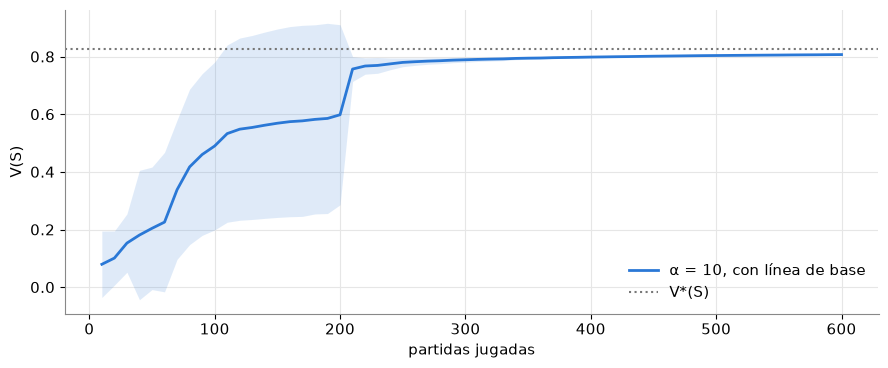

V(S) final de cada semilla: [0.8088, 0.8068, 0.8063, 0.809]   V* = 0.8262
aprendió (V(S) ≥ 0,75) en: [130, 250, 120, 170]


In [22]:
alfa_ej = 10.0           # TODO: probá 1, 3, 30
linea_base_ej = True     # TODO: probá False

cs_ej = [reinforce(env, alfa_ej, 600, sem, linea_base=linea_base_ej) for sem in range(4)]
xe = np.arange(1, 61) * 10
fig, ax = plt.subplots(figsize=(9, 3.8))
banda(ax, xe, np.array([c["VS"] for c in cs_ej]), COL_CON if linea_base_ej else COL_SIN,
      f"α = {alfa_ej:g}, {'con' if linea_base_ej else 'sin'} línea de base")
ax.axhline(V_estrella[env.start], color=COL_GRIS, ls=":", lw=1.5, label="V*(S)")
ax.set_xlabel("partidas jugadas"); ax.set_ylabel("V(S)"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
print("V(S) final de cada semilla:", [round(float(c["VS"][-1]), 4) for c in cs_ej], f"  V* = {V_estrella[env.start]:.4f}")
print("aprendió (V(S) ≥ 0,75) en:", [primera_vez(c["VS"], UMBRAL) for c in cs_ej])

In [23]:
eps_ej = 0.2             # TODO: probá 0.05, 0.5, 1.0, o None (sin recorte)
pasadas_ej = 50          # TODO: probá 5, 200

v_ej = []
for k in range(20):
    rng = random.Random(100 + k)
    lote = [jugar(env, theta_v, rng) for _ in range(10)]
    v_ej.append(valor_de(env, ppo_actualizar(theta_v, b_v, lote, 1.0, pasadas_ej, eps_ej)[0])[env.start])
v_ej = np.array(v_ej)
print(f"ε = {eps_ej}, {pasadas_ej} pasadas: V(S) antes = {V_antes:.4f}   después: media {v_ej.mean():.4f}, "
      f"mín. {v_ej.min():.4f}, máx. {v_ej.max():.4f}   mejoró en {np.sum(v_ej > V_antes)} de 20 lotes")

ε = 0.2, 50 pasadas: V(S) antes = 0.2178   después: media 0.3263, mín. 0.1569, máx. 0.4175   mejoró en 18 de 20 lotes


**Lo que encontramos** (¿qué $\alpha$ rompe a cada versión? ¿qué $\varepsilon$ deja de proteger? ¿qué pasa con pocas y con muchas pasadas?):

-

## Preguntas para pensar

1. En la sección 3, imitar ponderando superó al jugador del que aprendía. ¿Por qué clonar a un experto, sin pesos, no puede superarlo nunca? ¿Qué haría falta para que sí?
2. La línea de base convierte «esto salió bien» en «esto salió mejor de lo que esperaba». Piensen un ejemplo de la vida (un examen, un partido) en el que un buen resultado no debería reforzar nada, porque era lo esperado.
3. El actor-crítico depende de que el crítico sepa algo. ¿Qué pasaría si el crítico estuviera muy equivocado en una zona de la cueva por la que el actor tiene que pasar?

## Próxima clase

Hasta acá la recompensa venía dada: $+1$ al entrar a la salida. ¿Y si nadie sabe escribirla, pero sí puede decir cuál de dos trayectos prefiere? En la clase 12, **aprender la recompensa**: de comparaciones a un mapa de recompensa, y de ahí a cómo se ajustan los modelos de lenguaje con preferencias de personas (RLHF y DPO).